In [89]:
from dotenv import load_dotenv
load_dotenv()

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5.4-mini", stream_usage=True,temperature=0.7)


In [90]:
from pydantic import BaseModel,Field
from typing import Literal,Optional

class llm_schema(BaseModel):
    category:Literal['insta','twitter','linkedIn']=Field(description='category of the post to generate')
    topic:str=Field(description='topic of the post to generate')



In [91]:
llm_with_schema=llm.with_structured_output(llm_schema)

llm_with_schema.invoke('create a post about fifa wc 2026')

llm_schema(category='twitter', topic='FIFA World Cup 2026')

In [ ]:
from typing import Annotated
import operator

def take_latest(existing: str, new: str) -> str:
    return new

class graph_Schema(BaseModel):
    input: str
    topic: str = ""
    post: Annotated[str, operator.add] = ""
    category: Optional[Literal['insta', 'twitter', 'linkedIn']] = None

TypeError: Annotated[...] should be used with at least two arguments (a type and an annotation).

In [ ]:
def decider_node(state: graph_Schema) -> dict:
    result = llm_with_schema.invoke(state.input)
    return {"category": result.category, "topic": result.topic}

In [ ]:
def create_insta_post(state:graph_Schema) -> graph_Schema:
    
    topic=state.topic
    post=llm.invoke(f"create a insta post about {topic} and make teh content more engaging").content

    return {"post":post}


def create_twitter_post(state:graph_Schema) -> graph_Schema:
    
    topic=state.topic
    post=llm.invoke(f"create a twitter post about {topic} and make teh content more casual").content

    return {"post": post}

def create_linkedIn_post(state:graph_Schema) -> graph_Schema:
    
    topic=state.topic
    post=llm.invoke(f"create a linkedIn post about {topic} and make the content more informative and proffessional").content

    return {"post": post}




In [ ]:
def conditional(state:graph_Schema) -> str:
    category=state.category
    if category =='insta':
        return 'create_insta_post'
    elif category =='twitter':
        return 'create_twitter_post'
    elif category =='linkedIn':
        return 'create_linkedIn_post'
    else:
        raise ValueError('invalid category')


In [ ]:
from langgraph.graph import StateGraph, START, END

graph=StateGraph(graph_Schema)

graph.add_node("decider_node",decider_node)
graph.add_node("create_insta_post",create_insta_post)
graph.add_node("create_twitter_post",create_twitter_post)
graph.add_node("create_linkedIn_post",create_linkedIn_post)


graph.add_edge(START,'decider_node')
graph.add_conditional_edges('decider_node',conditional)
graph.add_edge('decider_node','create_insta_post')
graph.add_edge('decider_node','create_twitter_post')
graph.add_edge('decider_node','create_linkedIn_post')

graph.add_edge('create_insta_post',END)
graph.add_edge('create_twitter_post',END)
graph.add_edge('create_linkedIn_post',END)




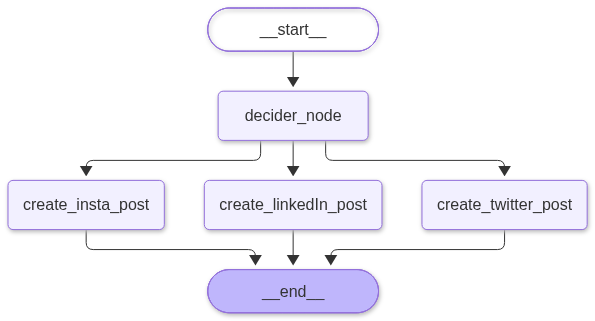

In [ ]:
## compile the graph 

from IPython.display import Image, display

Router_graph=graph.compile()


Image(Router_graph.get_graph().draw_mermaid_png())

In [ ]:
output = Router_graph.invoke({"input": "why arg lost the 2026 wc linkedin "})

output

{'input': 'why arg lost the 2026 wc linkedin ',
 'topic': 'Why Argentina lost the 2026 World Cup',
 'post': 'Here’s a casual Twitter-style post you can use:\n\n**Argentina didn’t lose the 2026 World Cup because they lacked talent — they lost it because football is brutal. One bad stretch, a few missed chances, and suddenly it’s over. That’s the game. Heartbreaking, but that’s why we love it.**\n\nIf you want, I can also make it:\n- more **funny**\n- more **spicy/opinionated**\n- more **short and viral**\n- more **neutral and analytical**',
 'category': 'linkedIn'}